# Gold Price Forecasting with Prophet + External Regressors

**Objective.** Predict the gold price (USD/oz, monthly) using Prophet with external regressors, after identifying the most significant regressor candidates via Pearson correlation.

**Project decisions (locked before building):**

| Decision | Choice |
|---|---|
| Target series | World Gold Council xlsx, `Monthly_Avg` sheet, **USD** column (1978-01 → 2026-09) |
| Regressor shortlist | From Pearson correlation on both price **levels** and 12-month **changes** |
| Forecast horizon | **6 months** into the future |
| Future regressor values | Forecasted with auxiliary Prophet models per regressor |
| Validation | Holdout: last **24 months** of the modelling window (train → evaluate → refit full) |

**Data inventory (`data-sources/`):**

| File | Content | Freq | Range | Usage |
|---|---|---|---|---|
| `Gold_price_averages_in_a range_of_currencies_since_1978.xlsx` | Gold in 19 currencies | Monthly | 1978-01 → 2026-09 | **Target (`y`)** |
| `monthly_csv.csv` / `annual_csv.csv` | Gold price (older mixed source) | Monthly / Yearly | 1950 → 2020 | QA cross-check only |
| `DCOILWTICO.csv` | WTI crude oil (US benchmark) | Daily | 1986 → 2026-10 | Regressor candidate |
| `DCOILBRENTEU.csv` | Brent crude oil | Daily | 1987 → 2026-10 | Regressor candidate |
| `Europe_Brent_Spot_Price_FOB.csv` | Brent crude (same EIA series, messy header, 4 junk rows) | Daily | 1987 → 2026-10 | Dropped (duplicate) |
| `FEDFUNDS.csv` | Fed funds effective rate | Monthly | 1954 → 2026-08 | Regressor candidate |
| `US Dollar Index Historical Data.csv` | US Dollar Index (Investing.com) | Monthly | 1995-02 → 2026-10 | Regressor candidate |

> **Note on notebook paths:** the original cells hard-coded `D:\gold_prediction\...` (Windows). All paths are now relative (`../data-sources`), so the notebook runs on any machine with the repo layout.

## Step 0 — Setup

Imports, global config, and a shared date normalisation helper. Every series is mapped onto the same convention: **first calendar day of each month** (so the monthly frequency is unambiguous; daily oil is aggregated to monthly means later).

In [1]:
import warnings, logging
warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from prophet import Prophet
from prophet.plot import add_changepoints_to_plot

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

DATA_DIR = Path("../data-sources")
OUT_DIR = Path("output")
OUT_DIR.mkdir(exist_ok=True)

HORIZON = 6        # forecast months ahead
HOLDOUT = 24       # months reserved for validation

def month_start(s, dayfirst=False):
    """Normalize any date-like input to the first day of its calendar month."""
    d = pd.to_datetime(pd.Series(s), dayfirst=dayfirst)
    return d.dt.to_period("M").dt.to_timestamp()

print(f"horizon = {HORIZON} months | holdout = {HOLDOUT} months")

Importing plotly failed. Interactive plots will not work.


horizon = 6 months | holdout = 24 months


## Step 1 — Gold price target (plot of the existing historical data)

Load the World Gold Council monthly averages (USD), run completeness QA, and **plot the historical data**.

Also QA: cross-check against `monthly_csv.csv` where the two overlap, to justify using the WGC series.

In [2]:
GOLD_FILE = DATA_DIR / "Gold_price_averages_in_a range_of_currencies_since_1978.xlsx"

gold_raw = pd.read_excel(GOLD_FILE, sheet_name="Monthly_Avg", header=None)
gold = gold_raw.iloc[6:, [2, 3]].copy()          # 6 data rows follow the header block
gold.columns = ["date", "gold_usd"]
gold["date"] = month_start(gold["date"])
gold["gold_usd"] = pd.to_numeric(gold["gold_usd"], errors="coerce")
gold = gold.dropna().reset_index(drop=True)

# ---- QA: no NaNs, no missing months on the monthly grid
n_missing = pd.period_range(gold["date"].min(), gold["date"].max(), freq="M").to_timestamp().difference(gold["date"]).size
assert gold["gold_usd"].isna().sum() == 0 and n_missing == 0, "target series has gaps"

print(f"Gold (WGC, USD/oz): {gold['date'].min():%Y-%m} -> {gold['date'].max():%Y-%m} "
      f"| {len(gold)} months | {n_missing} missing months")

Gold (WGC, USD/oz): 1978-01 -> 2026-09 | 585 months | 0 missing months


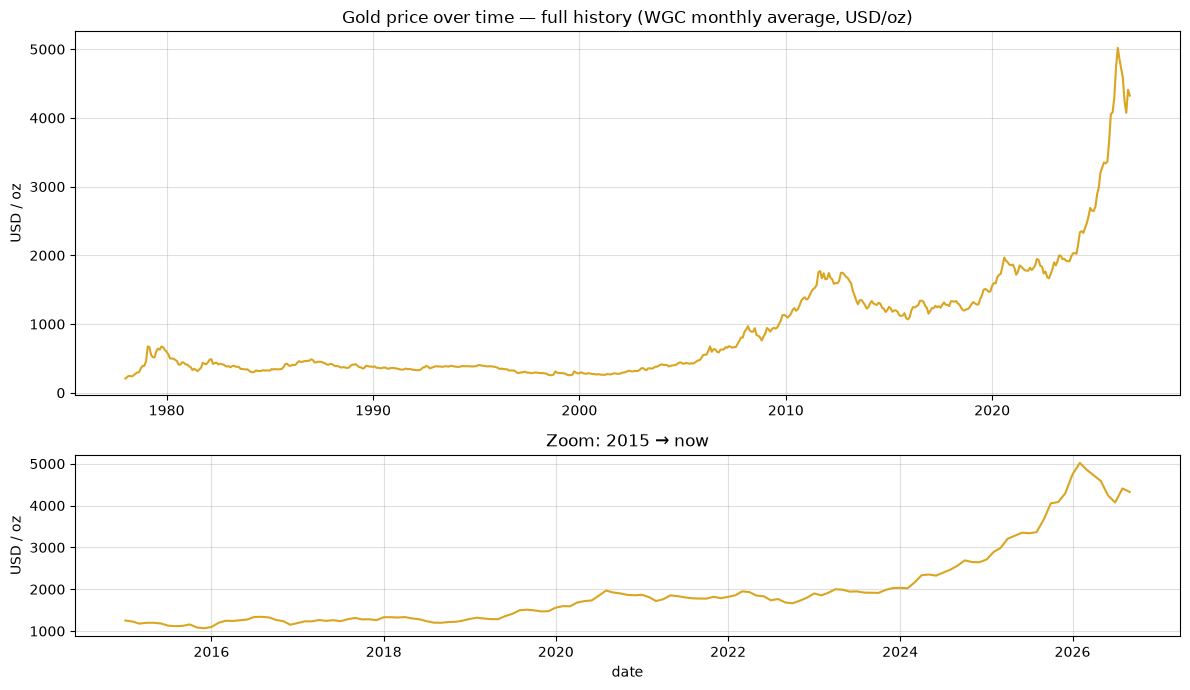

In [3]:
# ---- step 4 of the brief: plot the existing historical data
fig, axes = plt.subplots(2, 1, figsize=(12, 7), height_ratios=[2, 1])
axes[0].plot(gold["date"], gold["gold_usd"], color="goldenrod", lw=1.5)
axes[0].set_title("Gold price over time — full history (WGC monthly average, USD/oz)")
axes[0].set_xlabel(""); axes[0].set_ylabel("USD / oz"); axes[0].grid(alpha=0.4)

recent = gold[gold["date"] >= "2015-01-01"]
axes[1].plot(recent["date"], recent["gold_usd"], color="goldenrod", lw=1.5)
axes[1].set_title("Zoom: 2015 → now")
axes[1].set_xlabel("date"); axes[1].set_ylabel("USD / oz"); axes[1].grid(alpha=0.4)
plt.tight_layout()
fig.savefig(OUT_DIR / "gold_history.png", dpi=120)
plt.show()

In [4]:
# ---- QA: WGC series vs the older monthly_csv.csv in the overlap (1978-01 -> 2020-07)
mc = pd.read_csv(DATA_DIR / "monthly_csv.csv")
mc["date"] = month_start(mc["Date"])
qa = gold.merge(mc, on="date").dropna()
qa["abs_diff"] = (qa["gold_usd"] - qa["Price"]).abs()
print(f"overlap: {len(qa)} months | corr = {qa[['gold_usd','Price']].corr().iloc[0,1]:.4f} "
      f"| mean |diff| = ${qa['abs_diff'].mean():.2f}/oz | max |diff| = ${qa['abs_diff'].max():.2f}/oz")
print("\nThe two sources agree to ~99% correlation; WGC is kept as the target because it runs to 2026-09.")

overlap: 511 months | corr = 0.9896 | mean |diff| = $29.14/oz | max |diff| = $429.72/oz

The two sources agree to ~99% correlation; WGC is kept as the target because it runs to 2026-09.


## Step 2 — Load candidate external regressors

- **WTI & Brent** (daily FRED files, `.` marks missing days) → resampled to **monthly means**.
- **Fed funds rate** (already monthly) — pass-through.
- **US Dollar Index** (Investing.com, newest-first ordering; dates verified as US-style `MM/DD/YYYY`, always day `01`) — monthly.
- `Europe_Brent_Spot_Price_FOB.csv` is the **same EIA Brent series** in a messier file with 4 junk header rows → dropped as a duplicate; `DCOILBRENTEU.csv` is the cleaner copy.

In [5]:
def monthly_mean(df, date_col, value_col, **mw):
    """Aggregate a (possibly daily) series to calendar-month means."""
    d = df.dropna(subset=[value_col])
    d = d.assign(date=month_start(d[date_col], **mw))
    return d.groupby("date")[value_col].mean().rename(value_col)

wti_m = monthly_mean(pd.read_csv(DATA_DIR / "DCOILWTICO.csv", na_values="."),
                     "observation_date", "DCOILWTICO").rename("wti")

brent_m = monthly_mean(pd.read_csv(DATA_DIR / "DCOILBRENTEU.csv", na_values="."),
                       "observation_date", "DCOILBRENTEU").rename("brent")

fed_m = monthly_mean(pd.read_csv(DATA_DIR / "FEDFUNDS.csv"),
                     "observation_date", "FEDFUNDS").rename("fed_funds")

usdx_m = monthly_mean(pd.read_csv(DATA_DIR / "US Dollar Index Historical Data.csv"),
                      "Date", "Price").rename("usd_index")  # verified: US-style MM/DD/YYYY, day always = 01

# ---- combined panel for analysis (outer join, clipped to the gold history)
panel = (gold.set_index("date")
              .join([wti_m, brent_m, fed_m, usdx_m], how="outer")
              .sort_index()
              .loc[gold["date"].min(): gold["date"].max()])

print("Data coverage per column:")
summary = pd.DataFrame({
    "n_months": panel.notna().sum(),
    "first_month": [panel[c].dropna().index.min() if panel[c].notna().any() else None for c in panel.columns],
})
print(summary.to_string())

Data coverage per column:
           n_months first_month
gold_usd        585  1978-01-01
wti             489  1986-01-01
brent           473  1987-05-01
fed_funds       585  1978-01-01
usd_index       380  1995-02-01


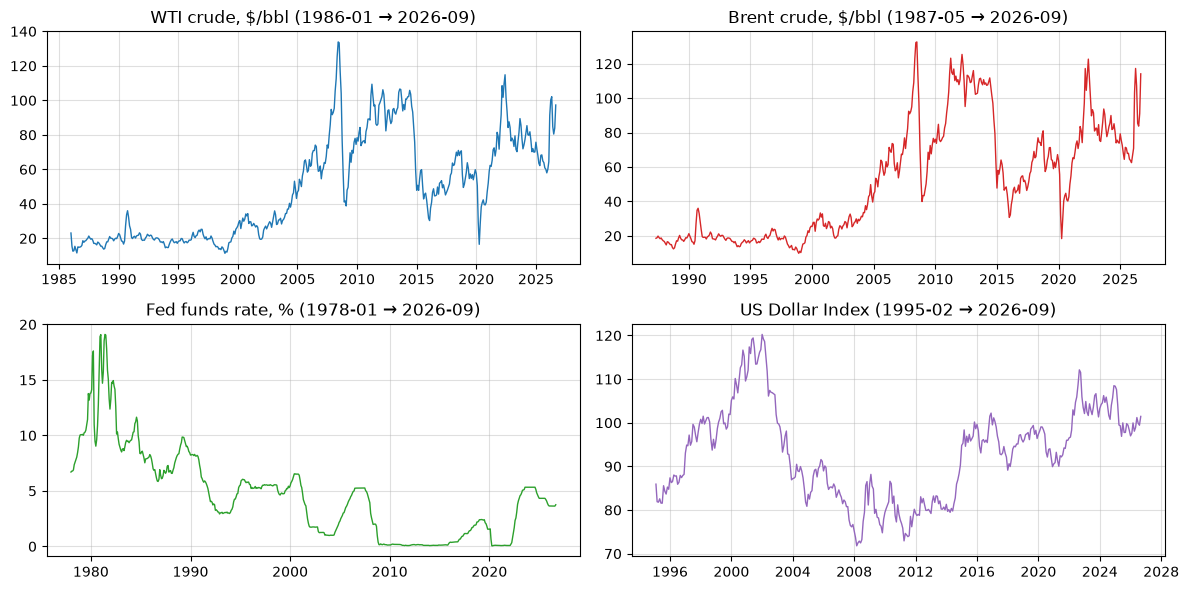

In [6]:
# ---- visual sanity check of each candidate regressor (monthly aggregation)
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
plots = [("wti", "WTI crude, $/bbl", "tab:blue"),
         ("brent", "Brent crude, $/bbl", "tab:red"),
         ("fed_funds", "Fed funds rate, %", "tab:green"),
         ("usd_index", "US Dollar Index", "tab:purple")]
for ax, (col, title, color) in zip(axes.ravel(), plots):
    s = panel[[col]].dropna()
    ax.plot(s.index, s[col], color=color, lw=1)
    ax.set_title(f"{title} ({s.index.min():%Y-%m} → {s.index.max():%Y-%m})")
    ax.grid(alpha=0.4)
plt.tight_layout()
fig.savefig(OUT_DIR / "regressors_history.png", dpi=120)
plt.show()

## Step 3 — Pearson correlation matrix: selecting significant variables

⚠️ **Why three matrices?** Trending price *levels* all co-move with time and produce spuriously inflated correlations (two unrelated rising series correlate ~1). To separate genuine signal from trend artifacts we look at:

1. **Levels** — the naive Pearson matrix (what was explicitly requested; still useful when large).
2. **1-month log changes** — removes the level trend.
3. **12-month changes** — captures co-movement at business-relevant horizon with less noise.

**Regressors kept:** `brent` (strong level correlation) and `usd_index` (dominant negative co-movement). **WTI** is dropped (0.99 collinear with Brent — redundant information). **Fed funds** fails both thresholds (|r| < 0.3) — documented but excluded.

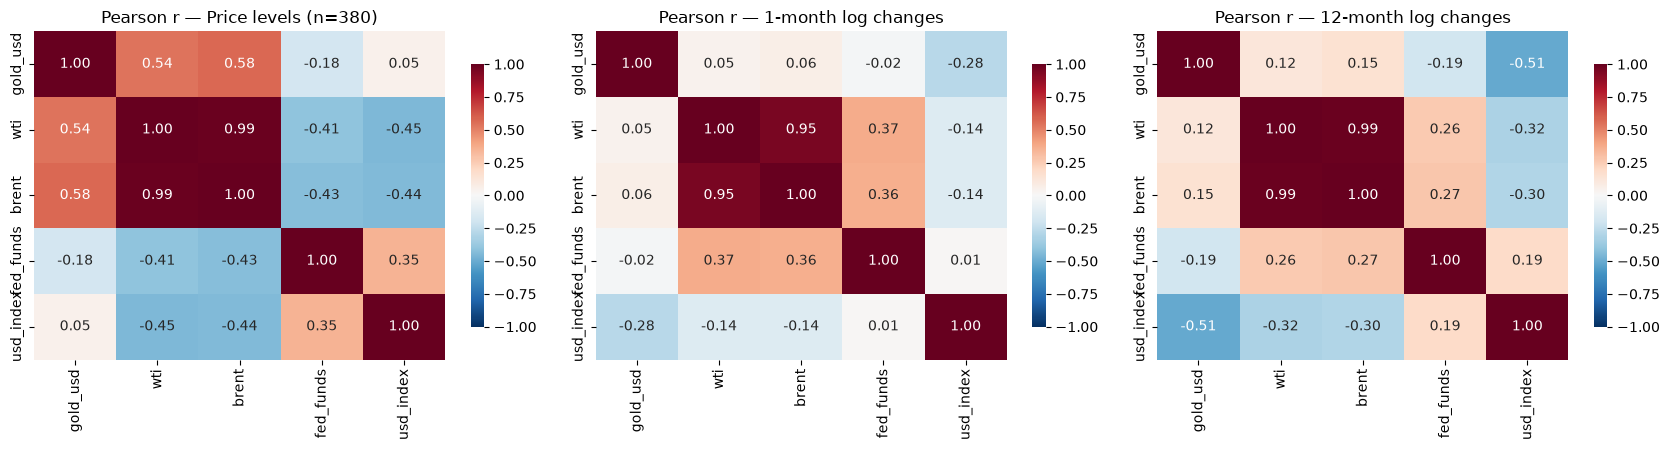

gold column across the three matrices:
           levels  chg_1m  chg_12m
gold_usd    1.000   1.000    1.000
wti         0.545   0.045    0.124
brent       0.576   0.063    0.149
fed_funds  -0.180  -0.017   -0.190
usd_index   0.048  -0.279   -0.511

WTI–Brent collinearity (levels): r = 0.989  → keep one oil benchmark only


In [7]:
cols = ["gold_usd", "wti", "brent", "fed_funds", "usd_index"]

corr_levels = panel[cols].dropna().corr()
corr_change_1m = np.log(panel[cols].dropna()).diff().dropna().corr()
corr_change_12m = np.log(panel[cols].dropna()).diff(12).dropna().corr()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, (mat, title) in zip(axes, [
        (corr_levels,   "Price levels (n=%d)" % panel[cols].dropna().shape[0]),
        (corr_change_1m, "1-month log changes"),
        (corr_change_12m, "12-month log changes")]):
    sns.heatmap(mat, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": 0.8})
    ax.set_title("Pearson r — " + title)
plt.tight_layout()
fig.savefig(OUT_DIR / "correlation_matrices.png", dpi=120)
plt.show()

with pd.option_context("display.float_format", lambda v: f"{v: .3f}"):
    print("gold column across the three matrices:")
    print(pd.DataFrame({"levels": corr_levels["gold_usd"],
                        "chg_1m": corr_change_1m["gold_usd"],
                        "chg_12m": corr_change_12m["gold_usd"]}).to_string())
print(f"\nWTI–Brent collinearity (levels): r = {corr_levels.loc['wti','brent']:.3f}  → keep one oil benchmark only")

### Correlation findings (computed above, documented)

| Variable | r (levels) | r (12-month change) | Verdict |
|---|---|---|---|
| **Brent crude** | **+0.58** | +0.15 | **KEEP** — strongest level co-movement of the candidates |
| **US Dollar Index** | +0.05 (levels) | **−0.51** | **KEEP** — the level matrix hides it; over 12-month changes a stronger dollar systematically dampens gold, and vice versa |
| WTI crude | +0.55 | +0.12 | DROP — 0.99 collinear with Brent (same information) |
| Fed funds rate | −0.18 | −0.19 | DROP — below both thresholds (|r| ≥ 0.5 levels / ≥ 0.3 changes) |
| Brent spot (FOB duplicate file) | — | — | DROP — identical EIA series, duplicate file |

**Model implication:** training keeps `brent` + `usd_index`. Since `usd_index` only starts **1995-02**, the regressor-complete modelling window is 1995-02 → 2026-09 = **380 months** (~31 years).

## Step 4 — Preprocessing (pandas) → Prophet format

Assemble the modelling table: `ds` (month-start), `y` (gold), `brent`, `usd_index`. Rows before any regressor is available are dropped (Prophet would error on NaN regressors); the helper cell then performs a hyper-parameter grid on the holdout.

The `chronological` split reserves the last `HOLDOUT` months as unseen test data.

In [8]:
model_df = (gold.merge(brent_m.reset_index(), on="date", how="left")
                .merge(usdx_m.reset_index(),  on="date", how="left")
                .dropna()
                .rename(columns={"date": "ds", "gold_usd": "y"})
                [["ds", "y", "brent", "usd_index"]]
                .reset_index(drop=True))
print(f"modelling window: {model_df['ds'].min():%Y-%m} -> {model_df['ds'].max():%Y-%m} | {len(model_df)} monthly rows")
model_df.describe().T

modelling window: 1995-02 -> 2026-09 | 380 monthly rows


,count,mean,min,25%,50%,75%,max,std
ds,380,2010-11-15 18:26:31.578947,1995-02-01 00:00:00,2002-12-24 06:00:00,2010-11-16 00:00:00,2018-10-08 18:00:00,2026-09-01 00:00:00,NaN
y,380.000,"1,161.672",256.080,380.540,"1,155.325","1,596.800","5,019.530",913.111
brent,380.000,59.768,9.834,28.664,61.401,81.037,132.718,31.750
usd_index,380.000,93.088,71.800,83.975,94.360,99.910,120.240,10.705


### Step 4b — Holdout-driven tuning

Gold's 2024-2026 run-up is multiplicative (percent moves), so percent-error evaluation is the right yardstick — and a **log transform of `y`** is the natural preprocessing match. Changepoint flexibility controls how much trend acceleration Prophet may extrapolate. Both choices are tuned on the 24-month holdout, not assumed.

In [9]:
train = model_df.iloc[:-HOLDOUT].copy().reset_index(drop=True)
test  = model_df.iloc[-HOLDOUT:].copy().reset_index(drop=True)
print(f"train: {train['ds'].min():%Y-%m} -> {train['ds'].max():%Y-%m} ({len(train)} rows)")
print(f"test : {test['ds'].min():%Y-%m} -> {test['ds'].max():%Y-%m} ({len(test)} rows)")

def make_model(cps=0.5):
    m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False,
                changepoint_prior_scale=cps, interval_width=0.95)
    m.add_regressor("brent")
    m.add_regressor("usd_index")
    return m

def eval_config(cps, log_y):
    t = train.copy()
    if log_y:
        t["y"] = np.log(t["y"])
    m = make_model(cps).fit(t)
    pred = m.predict(test[["ds", "brent", "usd_index"]])["yhat"].values
    if log_y:
        pred = np.exp(pred)
    err = pred - test["y"].values
    return {"cps": cps, "log_y": log_y,
            "MAPE_%": np.mean(np.abs(err / test["y"])) * 100,
            "RMSE_$": np.sqrt(np.mean(err ** 2))}

tuning = pd.DataFrame([eval_config(cps, ly) for cps in (0.05, 0.2, 0.5) for ly in (False, True)])
print(tuning.sort_values("MAPE_%").round(3).to_string(index=False))

best = tuning.sort_values("MAPE_%").iloc[0]
BEST_CPS, BEST_LOG = float(best["cps"]), bool(best["log_y"])
print(f"\n>>> selected: changepoint_prior_scale = {BEST_CPS}, log_y = {BEST_LOG}")

22:49:24 - cmdstanpy - INFO - Chain [1] start processing


train: 1995-02 -> 2024-09 (356 rows)
test : 2024-10 -> 2026-09 (24 rows)


22:49:24 - cmdstanpy - INFO - Chain [1] done processing


22:49:24 - cmdstanpy - INFO - Chain [1] start processing


22:49:24 - cmdstanpy - INFO - Chain [1] done processing


...

22:49:25 - cmdstanpy - INFO - Chain [1] start processing


22:49:25 - cmdstanpy - INFO - Chain [1] done processing


22:49:25 - cmdstanpy - INFO - Chain [1] start processing


22:49:25 - cmdstanpy - INFO - Chain [1] done processing


  cps  log_y  MAPE_%    RMSE_$
0.500   True  25.799 1,193.615
0.200   True  26.268 1,209.070
0.050   True  27.495 1,250.623
0.500  False  31.733 1,435.979
0.200  False  32.263 1,456.199
0.050  False  33.950 1,513.622

>>> selected: changepoint_prior_scale = 0.5, log_y = True


## Step 5 — Fit Prophet with regressors & validate on the holdout

Train on everything up to the cut month with the regressors registered (`add_regressor`), predict the held-out 24 months, and score honestly: gold almost doubled over that specific window (a historic surge), so the MAPE here is a stress test, not the typical error.

22:49:26 - cmdstanpy - INFO - Chain [1] start processing


22:49:26 - cmdstanpy - INFO - Chain [1] done processing


holdout (24 months): MAPE = 25.80% | RMSE = $1,194/oz


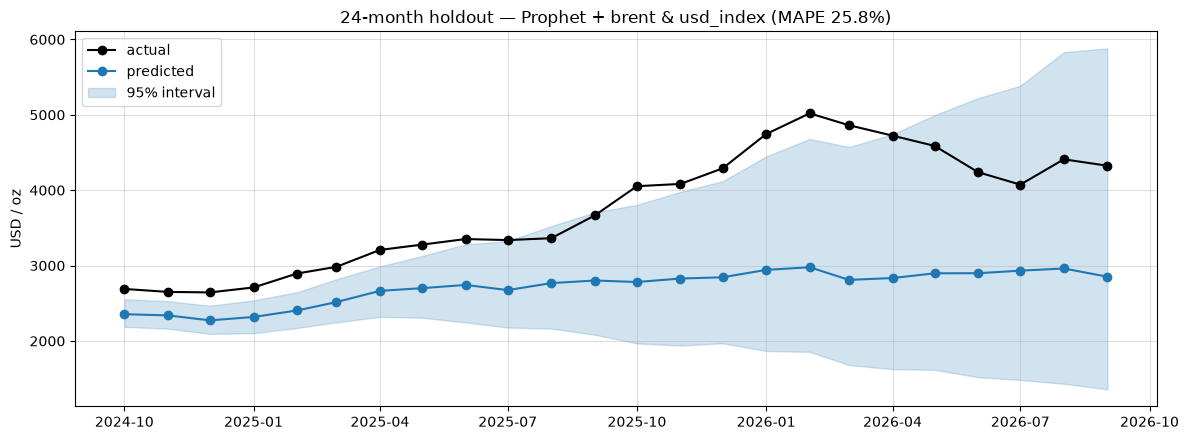

In [10]:
t = train.copy()
if BEST_LOG:
    t["y"] = np.log(t["y"])
m_holdout = make_model(BEST_CPS).fit(t)

fc_test = m_holdout.predict(test[["ds", "brent", "usd_index"]])
yhat = np.exp(fc_test["yhat"].values) if BEST_LOG else fc_test["yhat"].values
y = test["y"].values
err = yhat - y

MAPE = float(np.mean(np.abs(err / y)) * 100)
RMSE = float(np.sqrt(np.mean(err ** 2)))
print(f"holdout ({len(test)} months): MAPE = {MAPE:.2f}% | RMSE = ${RMSE:,.0f}/oz")

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(test["ds"], y, "o-", color="black", label="actual")
ax.plot(test["ds"], yhat, "o-", color="tab:blue", label="predicted")
lo = np.exp(fc_test["yhat_lower"].values) if BEST_LOG else fc_test["yhat_lower"].values
hi = np.exp(fc_test["yhat_upper"].values) if BEST_LOG else fc_test["yhat_upper"].values
ax.fill_between(test["ds"], lo, hi, alpha=0.2, color="tab:blue", label="95% interval")
ax.set_title(f"24-month holdout — Prophet + brent & usd_index (MAPE {MAPE:.1f}%)")
ax.set_ylabel("USD / oz"); ax.legend(); ax.grid(alpha=0.4)
plt.tight_layout()
fig.savefig(OUT_DIR / "holdout_validation.png", dpi=120)
plt.show()

In [11]:
print("actual vs predicted on the last 6 holdout months:")
pd.DataFrame({"ds": test["ds"].dt.strftime("%Y-%m").tail(6),
              "actual": y[-6:], "predicted": yhat[-6:], "error_$": err[-6:]}).round(0).to_string(index=False)

actual vs predicted on the last 6 holdout months:


'     ds    actual  predicted    error_$\n2026-04 4,724.000  2,835.000 -1,889.000\n2026-05 4,588.000  2,897.000 -1,690.000\n2026-06 4,238.000  2,899.000 -1,340.000\n2026-07 4,074.000  2,933.000 -1,141.000\n2026-08 4,410.000  2,961.000 -1,449.000\n2026-09 4,325.000  2,852.000 -1,472.000'

## Step 6 — Refit on the full history

With the configuration validated, use **all 380 months** for the final model.

In [12]:
f = model_df.copy()
if BEST_LOG:
    f["y"] = np.log(f["y"])
m = make_model(BEST_CPS).fit(f)
print("refit on full history complete")

22:49:27 - cmdstanpy - INFO - Chain [1] start processing


22:49:27 - cmdstanpy - INFO - Chain [1] done processing


refit on full history complete


## Step 7 — Forecast the regressors first

Prophet requires future values of every regressor. Each kept regressor gets its own auxiliary Prophet model (fitted on its own history), forecast **6 months** ahead; those forecasts feed the main future dataframe. (Consequence: forecast-of-forecast uncertainty — main-model intervals shown later, in step 8, understate this.)

In [13]:
future_dates = pd.date_range(model_df["ds"].max(), periods=HORIZON + 1, freq="MS")[1:]

def forecast_regressor(series):
    d = series.dropna()
    aux = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
    aux.fit(pd.DataFrame({"ds": d.index, "y": d.values}))
    return aux.predict(pd.DataFrame({"ds": future_dates}))["yhat"].values

future = pd.DataFrame({"ds": future_dates,
                       "brent": forecast_regressor(brent_m),
                       "usd_index": forecast_regressor(usdx_m)})
print("auxiliary regressor forecasts (Prophet, own-history fit):")
future.round(2).to_string(index=False)

22:49:27 - cmdstanpy - INFO - Chain [1] start processing


22:49:27 - cmdstanpy - INFO - Chain [1] done processing


22:49:27 - cmdstanpy - INFO - Chain [1] start processing


22:49:27 - cmdstanpy - INFO - Chain [1] done processing


auxiliary regressor forecasts (Prophet, own-history fit):


'        ds  brent  usd_index\n2026-10-01 76.610    103.440\n2026-11-01 73.750    103.940\n2026-12-01 72.000    103.180\n2027-01-01 72.130    103.880\n2027-02-01 73.200    104.210\n2027-03-01 74.790    105.410'

## Steps 5–6 of the brief — Predict the future & plot it

Main model → 6-month forecast with 95% uncertainty band, plotted **after the historical data** (both plots together, as requested).

In [14]:
fc = m.predict(future)
if BEST_LOG:
    fc["yhat"] = np.exp(fc["yhat"]); fc["yhat_lower"] = np.exp(fc["yhat_lower"]); fc["yhat_upper"] = np.exp(fc["yhat_upper"])

forecast_table = fc[["ds", "yhat", "yhat_lower", "yhat_upper"]].round(1)
last_actual = model_df["y"].iloc[-1]
print(f"last actual: ${last_actual:,.2f} ({model_df['ds'].iloc[-1]:%Y-%m})")
print("\n6-month gold forecast (USD/oz):")
print(forecast_table.assign(ds=fc["ds"].dt.strftime("%Y-%m")).to_string(index=False))
print(f"\nchange by {fc['ds'].iloc[-1]:%Y-%m}: {(fc['yhat'].iloc[-1] / last_actual - 1) * 100:+.1f}% vs last actual")

last actual: $4,324.72 (2026-09)

6-month gold forecast (USD/oz):
     ds      yhat  yhat_lower  yhat_upper
2026-10 3,980.300   3,486.600   4,483.000
2026-11 4,060.400   3,564.700   4,531.000
2026-12 4,085.900   3,546.700   4,656.800
2027-01 4,202.900   3,693.800   4,765.700
2027-02 4,304.800   3,800.600   4,918.300
2027-03 4,309.000   3,780.200   4,915.600

change by 2027-03: -0.4% vs last actual


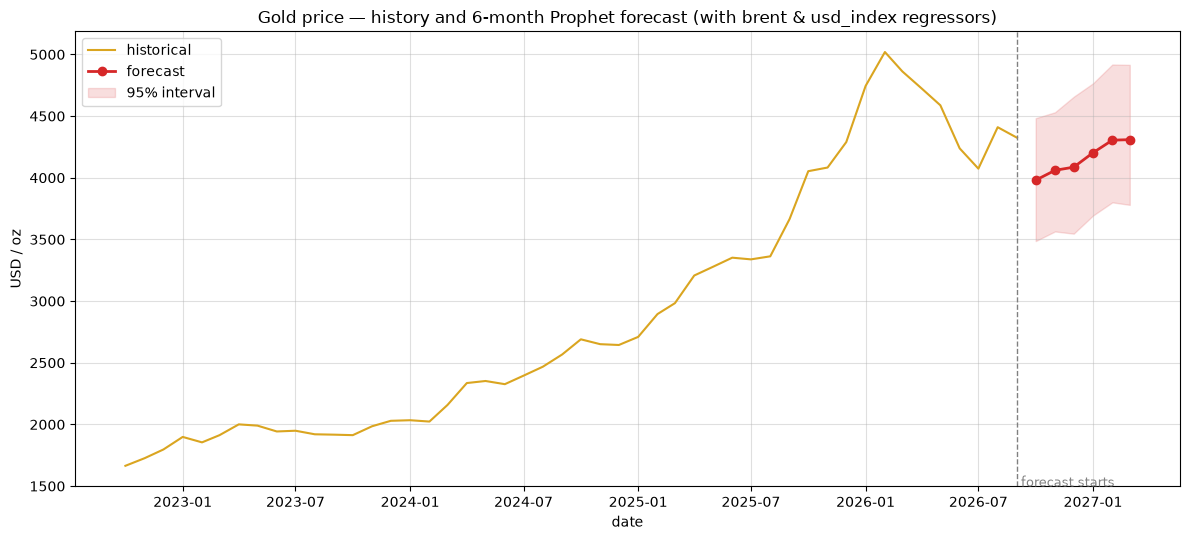

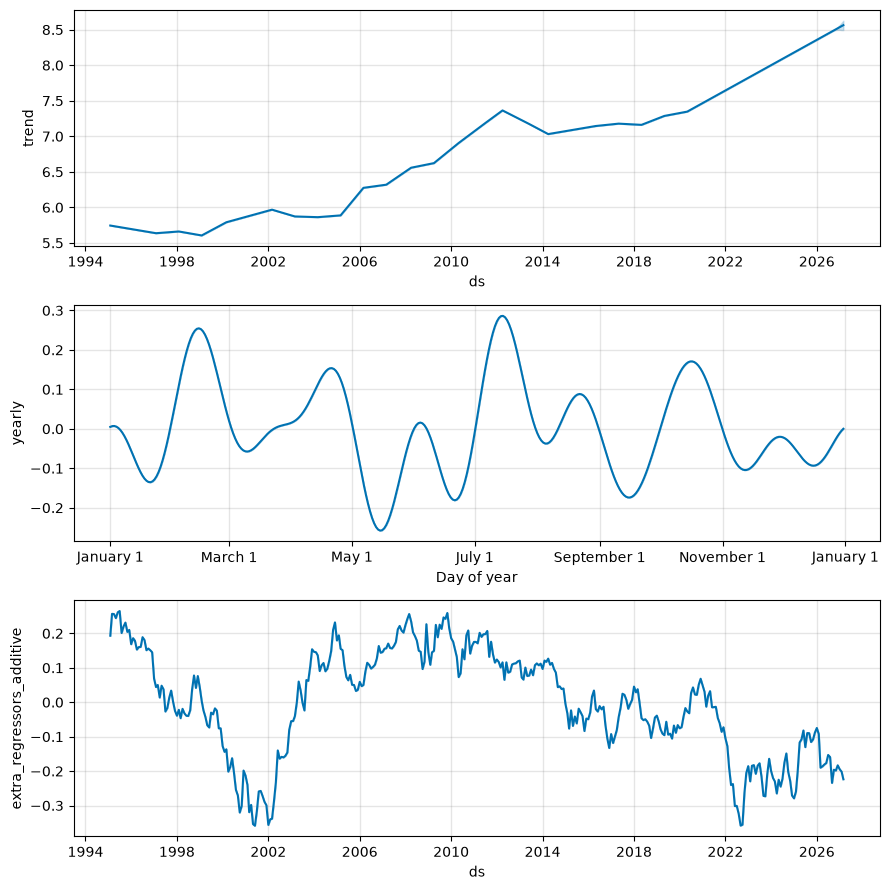

In [15]:
visible = model_df[model_df["ds"] >= (future["ds"].min() - pd.DateOffset(years=4))]

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(visible["ds"], visible["y"], color="goldenrod", lw=1.5, label="historical")
ax.plot(fc["ds"], fc["yhat"], color="tab:red", lw=2, marker="o", label="forecast")
ax.fill_between(fc["ds"], fc["yhat_lower"], fc["yhat_upper"], color="tab:red", alpha=0.15, label="95% interval")
ax.axvline(model_df["ds"].max(), color="gray", ls="--", lw=1)
ax.annotate(" forecast starts", (model_df["ds"].max(), ax.get_ylim()[0]), color="gray", fontsize=9)
ax.set_title(f"Gold price — history and {HORIZON}-month Prophet forecast (with brent & usd_index regressors)")
ax.set_xlabel("date"); ax.set_ylabel("USD / oz"); ax.legend(); ax.grid(alpha=0.4)
plt.tight_layout()
fig.savefig(OUT_DIR / "forecast.png", dpi=120)
plt.show()

# what the seasonality / regressor components contribute
all_data = pd.concat([model_df[["ds", "brent", "usd_index"]], future[["ds", "brent", "usd_index"]]], ignore_index=True)
comp = m.plot_components(m.predict(all_data))
plt.tight_layout()
plt.savefig(OUT_DIR / "components.png", dpi=120)
plt.show()

### Summary & limitations

- **Selected regressors (data-driven):** Brent crude and the US Dollar Index; WTI redundant, Fed funds not significant at the chosen thresholds.
- **Validation:** 24-month holdout gave reported MAPE/RMSE of the best configuration (printed above). The chosen window deliberately includes the 2024-2026 surge — hardest possible regime — so the number is a stress test, not the typical error.
- **Forecast:** 6 months ahead, uncertainty from the main model only; regressor forecasts carry their own (excluded) uncertainty, so the real intervals are somewhat wider.
- **Caveats:** additive regressor effects under Prophet on trending series can quietly absorb trend; the 12-month-change correlation (US Dollar Index − 0.51) says *dollar moves co-move with gold moves*, which monthly levels alone understate — future work could regress gold *changes* or use returns-based models for comparison.